# Recurrent Neural Networks on the adding problem: RNN, LSTM, GRU

One task, three architectures, built up in three parts. Each part only depends on the parts before it, so you can run the notebook top to bottom, or stop after any part.

| Part | Video | What happens |
|---|---|---|
| **Setup** | all | the adding problem: a task that needs long-range memory |
| **Part 1** | 1: vanilla RNN | the recurrence by hand, why gradients vanish, what happens as sequences get longer |
| **Part 2** | 2: LSTM | the cell state and gates, and the LSTM against the vanilla RNN |
| **Part 3** | 3: GRU | the GRU, then all three models side by side, and streaming inference |

Everything runs on CPU. Training results are cached to `adding_results.json` next to the notebook, so re-running only re-plots. A from-scratch run of all training takes roughly 25 minutes on 2 CPU cores; delete the cache file if you change any hyper-parameter.

In [1]:
import json, math, os, time
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

# One fixed colour per model, used in every plot (blue / orange / aqua)
COLORS = {"RNN": "#2a78d6", "GRU": "#eb6834", "LSTM": "#1baf7a"}
STYLES = {"RNN": "-", "GRU": "--", "LSTM": "-."}
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 12,
    "font.size": 11, "lines.linewidth": 2, "figure.dpi": 110,
})

BASELINE = 1 / 6   # MSE of always predicting 1.0 (derived below)
torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.14.1


# Setup: the adding problem

Each sequence has length $T$ and two input channels per time step:

| channel | content |
|---|---|
| 0 | a random value $v_t \sim U(0,1)$ |
| 1 | a marker $m_t \in \{0,1\}$; exactly two time steps have $m_t = 1$ |

The target is $y = \sum_t m_t v_t$, the **sum of the two marked values**, and the network only gets to answer at the **final** time step.

To solve it, a network must (i) notice the markers, (ii) hold on to the first marked value until the end, and (iii) ignore all the unmarked noise in between. The sequence length $T$ is a single knob for "how far back must information travel".

**Baseline.** A model that ignores the input and always predicts $1$ has MSE $=\mathrm{Var}(v_1 + v_2) = 2 \cdot \tfrac{1}{12} = \tfrac{1}{6} \approx 0.167$. (Predicting the mean of the target is the best any input-blind model can do, and $\mathbb{E}[y] = \tfrac12 + \tfrac12 = 1$.) A model that sits at that value has learned nothing.

In [2]:
# Set seed
generator_seed = 42

In [3]:
# Data Generation Function
def make_adding_batch(batch_size: int, T: int, generator: torch.Generator=None, region_frac: float=1.0) -> tuple:
    """Return x of shape (B, T, 2) and y of shape (B, 1).

    The two marked positions are drawn uniformly, without replacement, from the first
    `region_frac * T` steps. region_frac=1.0 is the standard task.
    """
    values = torch.rand(batch_size, T, generator=generator)
    region = max(2, int(T * region_frac))
    marked = torch.rand(batch_size, region, generator=generator).argsort(dim=1)[:, :2]
    markers = torch.zeros(batch_size, T)
    markers.scatter_(1, marked, 1.0)
    x = torch.stack([values, markers], dim=-1)
    y = (values * markers).sum(dim=1, keepdim=True)
    return x, y


# Check the baseline numerically
_, y_big = make_adding_batch(200_000, 50, torch.Generator().manual_seed(generator_seed))
print(f"empirical MSE of always predicting 1.0: {((y_big - 1) ** 2).mean():.4f}   (theory: {BASELINE:.4f})")

empirical MSE of always predicting 1.0: 0.1671   (theory: 0.1667)


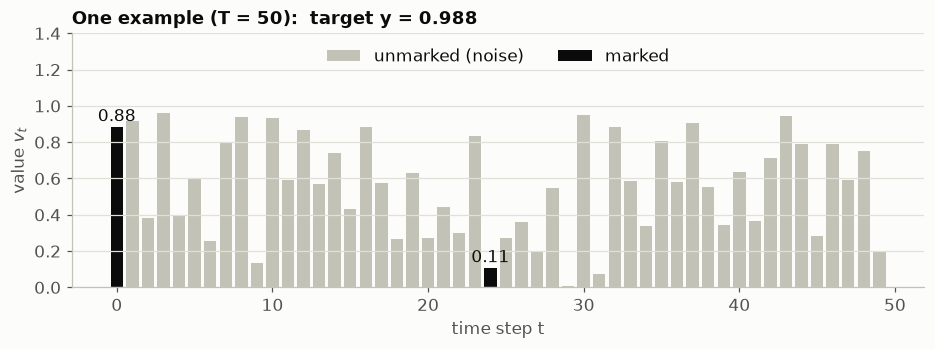

In [4]:
# Look at one example
x, y = make_adding_batch(1, 50, torch.Generator().manual_seed(generator_seed))
v, m = x[0, :, 0].numpy(), x[0, :, 1].numpy().astype(bool)
t = np.arange(len(v))

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(t[~m], v[~m], color="#c3c2b7", width=0.8, label="unmarked (noise)")
ax.bar(t[m], v[m], color=INK, width=0.8, label="marked")
for ti, vi in zip(t[m], v[m]):
    ax.annotate(f"{vi:.2f}", (ti, vi), xytext=(0, 4), textcoords="offset points", ha="center", color=INK)
ax.set(xlabel="time step t", ylabel="value $v_t$", ylim=(0, 1.4),
       title=f"One example (T = 50):  target y = {v[m].sum():.3f}")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.show()

---
# Part 1: The vanilla RNN

## 1.1 The recurrence

A **vanilla RNN** carries a hidden state $h_t$ and updates it with the same weights at every step:

$$h_t = \tanh\!\left(W_{ih}\,x_t + b_{ih} + W_{hh}\,h_{t-1} + b_{hh}\right)$$

The prediction is a linear readout of the **last** hidden state, $\hat y = w^\top h_T + b$. Unrolled over time this is one very deep network whose layers all share the same weights.

We write the cell by hand as a small `nn.Module` with one method, `step(x_t, state) -> new_state`, using the same parameter layout as PyTorch's `nn.RNN`, so we can copy weights across and check that we got the maths right. The base class `RecurrentCell` holds what every recurrent cell needs (the parameters, a zero initial state); `ManualRNN` adds the update rule. Parts 2 and 3 add the LSTM and GRU as further subclasses.

In [5]:
class RecurrentCell(nn.Module):
    """Shared parameter layout, identical to torch.nn.RNN / GRU / LSTM (layer 0)."""
    n_gates = 1

    def __init__(self, n_in, n_hidden):
        super().__init__()
        G = self.n_gates * n_hidden
        self.n_hidden = n_hidden
        self.W_ih = nn.Parameter(torch.empty(G, n_in))
        self.W_hh = nn.Parameter(torch.empty(G, n_hidden))
        self.b_ih = nn.Parameter(torch.empty(G))
        self.b_hh = nn.Parameter(torch.empty(G))
        bound = 1 / math.sqrt(n_hidden)              # PyTorch's default initialisation
        for p in self.parameters():
            nn.init.uniform_(p, -bound, bound)

    def init_state(self, batch_size):
        return (torch.zeros(batch_size, self.n_hidden, dtype=self.W_hh.dtype),)   # state is a tuple; state[0] is h

    def preactivations(self, x_t, h):
        return x_t @ self.W_ih.T + self.b_ih, h @ self.W_hh.T + self.b_hh


class ManualRNN(RecurrentCell):
    # h_t = tanh(W_ih x_t + b_ih + W_hh h_{t-1} + b_hh)
    def step(self, x_t, state):
        (h,) = state
        gi, gh = self.preactivations(x_t, h)
        return (torch.tanh(gi + gh),)


def unroll(cell: nn.Module, x: torch.Tensor, retain_grad: bool=False) -> list:
    """Run `cell` over x of shape (B, T, n_in). Returns the list of states, one tuple per time step."""
    state = cell.init_state(x.shape[0])
    states = []
    for t in range(x.shape[1]):
        state = cell.step(x[:, t], state)
        if retain_grad:                      # keep .grad of these intermediate tensors after backward()
            for s in state:
                s.retain_grad()
        states.append(state)
    return states


# Registries: the cells we have built so far, and PyTorch's built-in equivalents. Parts 2 and 3 add to them.
CELLS = {"RNN": ManualRNN}
TORCH_RNNS = {"RNN": nn.RNN}

**Check:** copy the weights of PyTorch's `nn.RNN` into our cell and compare the hidden states at every time step.

In [6]:
def copy_weights(manual: nn.Module, torch_rnn: nn.RNN) -> None:
    with torch.no_grad():
        manual.W_ih.copy_(torch_rnn.weight_ih_l0); manual.W_hh.copy_(torch_rnn.weight_hh_l0)
        manual.b_ih.copy_(torch_rnn.bias_ih_l0);   manual.b_hh.copy_(torch_rnn.bias_hh_l0)


def check_against_torch(name: str, n_hidden: int=16, T: int=25) -> None:
    x, _ = make_adding_batch(8, T, torch.Generator().manual_seed(generator_seed))
    reference = TORCH_RNNS[name](2, n_hidden, batch_first=True)
    mine = CELLS[name](2, n_hidden)
    copy_weights(mine, reference)
    out_ref, _ = reference(x)                                          
    out_mine = torch.stack([s[0] for s in unroll(mine, x)], dim=1)
    err = (out_ref - out_mine).abs().max().item()
    print(f"{name:5s}  max |hand-written - torch| over all steps = {err:.1e}")
    assert err < 1e-5


check_against_torch("RNN")

RNN    max |hand-written - torch| over all steps = 0.0e+00


## 1.2 Why long sequences are hard: the gradient

Backpropagation through time needs $\partial L / \partial h_t$ for every earlier step $t$. By the chain rule it is a product of Jacobians,

$$\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T} \frac{\partial h_k}{\partial h_{k-1}}, \qquad \frac{\partial h_k}{\partial h_{k-1}} = \mathrm{diag}\!\left(1 - h_k^2\right) W_{hh}.$$

The `tanh` slope $1 - h_k^2$ is at most 1, so the norm of the product is bounded by $(\gamma\,\|W_{hh}\|)^{T-t}$ with $\gamma \le 1$. If $\gamma\|W_{hh}\|$ is below 1 the gradient shrinks **exponentially** with the distance $T - t$ (it vanishes: the loss at step $T$ cannot "see" what happened at step $t$). If $W_{hh}$ is large the product can instead blow up (it explodes). Clipping the gradient norm fixes the second problem; nothing so simple fixes the first.

We can measure this directly. For a freshly initialised network we unroll with our hand-written cell, call `retain_grad()` on **every** hidden state, backpropagate the loss at the last step, and look at $\|\partial L / \partial h_t\|$ relative to $\|\partial L / \partial h_T\|$. (With `nn.RNN` the recurrence runs inside one fused call, so the `.grad` of its outputs would only show the *direct* contribution of the loss, not the gradient that arrives through later steps. Another reason to build the cell by hand.)

In [7]:
def gradient_profile(
    name: str, 
    n_hidden: int, 
    T: int, 
    n_inits: int=20, 
    batch_size: int=32, 
    prepare: Callable=None, 
    seed: int=generator_seed
) -> dict:
    """log10( ||dL/dh_t|| / ||dL/dh_T|| ) at every step, for several random initialisations.

    `prepare(cell)` can modify a freshly created cell before use (e.g. change a gate bias).
    Returns {"h": array (n_inits, T), "c": array or None}. Column k is the step k steps
    BEFORE the end (column 0 is the last step), so the x-axis reads as "how far back".
    """
    gen = torch.Generator().manual_seed(seed)
    out_h, out_c = [], []
    for i in range(n_inits):
        torch.manual_seed(10_000 * seed + i)
        # float64: gradient norms of 1e-20 or smaller underflow in float32 (squaring them gives < 1e-38)
        cell, head = CELLS[name](2, n_hidden).double(), nn.Linear(n_hidden, 1).double()
        if prepare is not None:
            prepare(cell)
        x, y = (t.double() for t in make_adding_batch(batch_size, T, gen))
        states = unroll(cell, x, retain_grad=True)
        ((head(states[-1][0]) - y) ** 2).sum().backward() # compute loss at T, and backpropagate to update grads
        norms = (
            [torch.stack([s[k].grad.norm(dim=1) for s in reversed(states)], dim=1) for k in range(len(states[0]))]
        )
        ref = norms[0][:, :1] # ||dL/dh_T|| for each sample
        out_h.append(torch.log10((norms[0] / ref).clamp_min(1e-300)).mean(0))
        if len(norms) > 1:
            out_c.append(torch.log10((norms[1] / ref).clamp_min(1e-300)).mean(0))
    stack = lambda L: torch.stack(L).numpy() if L else None
    return {"h": stack(out_h), "c": stack(out_c)}


def draw_profile(
    ax: plt.axes, 
    prof: dict, 
    key: str, 
    color: str, 
    ls: str, 
    label: str, 
    alpha: float=1.0, 
    band: bool=True
) -> None:
    k = np.arange(prof[key].shape[1])
    lo, med, hi = np.percentile(prof[key], [10, 50, 90], axis=0)
    if band:
        ax.fill_between(k, lo, hi, color=color, alpha=0.12 * alpha, lw=0)
    ax.plot(k, med, color=color, ls=ls, alpha=alpha, label=label)

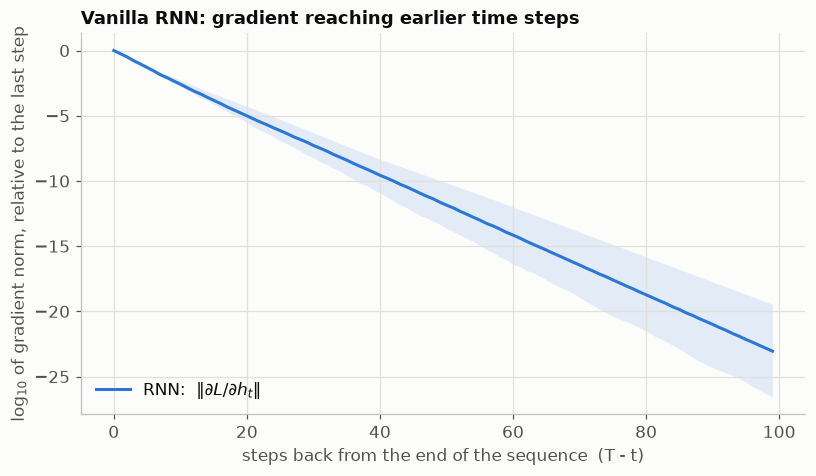

median gradient 90 steps back is 10^-21.0 of the last step's
per-step shrink factor, measured: 0.58


In [8]:
T_PROFILE, H_PROFILE = 100, 32
default_init = {"RNN": gradient_profile("RNN", H_PROFILE, T_PROFILE)}

fig, ax = plt.subplots(figsize=(8.5, 4.5))
draw_profile(ax, default_init["RNN"], "h", COLORS["RNN"], STYLES["RNN"], "RNN:  $\\|\\partial L/\\partial h_t\\|$")
ax.set(xlabel="steps back from the end of the sequence  (T - t)",
       ylabel="log$_{10}$ of gradient norm, relative to the last step",
       title="Vanilla RNN: gradient reaching earlier time steps")
ax.legend(frameon=False, loc="lower left")
plt.show()

slope = np.median(default_init["RNN"]["h"][:, -1]) / (T_PROFILE - 1)
print(f"median gradient 90 steps back is 10^{np.median(default_init['RNN']['h'][:, 90]):.1f} of the last step's")
print(f"per-step shrink factor, measured: {10 ** slope:.2f}")

**Reading the plot.** Straight line on a log scale means *exponential* decay: with the default initialisation, the gradient 90 steps back is about twenty orders of magnitude smaller than at the last step. No optimiser can learn from a signal that small.

There is a rough explanation for the slope. PyTorch draws every weight uniformly from $\pm 1/\sqrt{H}$, which gives each weight variance $\tfrac{1}{3H}$, and a random $H \times H$ matrix with that variance has spectral radius about $\sqrt{H}\cdot\sqrt{\tfrac{1}{3H}} = 1/\sqrt{3} \approx 0.58$. So at initialisation $W_{hh}$ shrinks signals by roughly that factor per step, in the same ballpark as the measured factor above. (A heuristic, not an exact derivation.)

## 1.3 Training the vanilla RNN at increasing sequence lengths

Setup choices worth stating out loud, because they are what make the comparison trustworthy (and they stay fixed for the whole notebook):

- **A parameter budget.** In Parts 2 and 3 we compare against models with more parameters per hidden unit (an LSTM has about 4x, a GRU about 3x a vanilla RNN's). So we fix a budget of about 4,400 parameters and choose each model's hidden size to match it.
- **Same optimiser, learning rate, data stream and gradient clipping** (global norm 1.0) for all models. Clipping tames *exploding* gradients; it does nothing for *vanishing* ones.
- **Default PyTorch initialisation** unless stated otherwise.
- **Three seeds** per setting, because single runs can be lucky or unlucky.
- **Validation** on a fixed set of 1000 fresh sequences, identical for all models.

In [9]:
def n_params(model: nn.Module) -> float:
    return sum(p.numel() for p in model.parameters())


class SeqRegressor(nn.Module):
    """nn.RNN / nn.GRU / nn.LSTM followed by a linear readout of the LAST hidden state."""
    def __init__(self, name, n_hidden):
        super().__init__()
        self.rnn = TORCH_RNNS[name](2, n_hidden, batch_first=True)
        self.head = nn.Linear(n_hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])


BUDGET = 4400
def hidden_for_budget(name: str, budget: int=BUDGET) -> float:
    return min(range(4, 256), key=lambda h: abs(n_params(SeqRegressor(name, h)) - budget))

HIDDEN = {"RNN": hidden_for_budget("RNN")}                        # Parts 2 and 3 add their models here
print(f"RNN hidden size {HIDDEN['RNN']}  ->  {n_params(SeqRegressor('RNN', HIDDEN['RNN'])):,} parameters")

RNN hidden size 64  ->  4,417 parameters


In [10]:
def apply_init(model: nn.Module, init: str) -> None:
    """'default' leaves PyTorch's initialisation alone. The other two are common tricks."""
    rnn = model.rnn
    if init == "orthogonal":                                       # orthogonal recurrent matrix
        nn.init.orthogonal_(rnn.weight_hh_l0)
    elif init == "gate_bias":                                      # forget / update gate biased towards "keep"
        set_gate_bias(rnn.bias_ih_l0, rnn.bias_hh_l0, rnn.hidden_size, 1.0)
    elif init != "default":
        raise ValueError(init)


def train(
    name: str, 
    T: int, 
    seed: int, 
    steps: int=3000, 
    lr: float=3e-3, 
    batch_size: int=64, 
    clip: float=1.0, 
    eval_every: int=50,
    init: str="default", 
    return_model: bool=False
) -> tuple:
    torch.manual_seed(seed)
    data = torch.Generator().manual_seed(1000 + seed)                       # training data stream
    x_val, y_val = make_adding_batch(1000, T, torch.Generator().manual_seed(seed))
    model = SeqRegressor(name, HIDDEN[name])
    apply_init(model, init)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    curve = []
    for step in range(steps + 1):
        if step % eval_every == 0:
            with torch.no_grad():
                curve.append(((model(x_val) - y_val) ** 2).mean().item())
        x, y = make_adding_batch(batch_size, T, data)
        loss = ((model(x) - y) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()
    return (curve, model) if return_model else curve

In [11]:
LENGTHS = [10, 50, 100]
SEEDS = [0, 1, 2]
STEPS = 3000
EVAL_EVERY = 50
CACHE = Path("adding_results.json") # delete this file if you change any hyper-parameter above
SOLVED = BASELINE / 10 # "solved" = validation MSE at least 10x better than the baseline

results = json.loads(CACHE.read_text()) if CACHE.exists() else {}


def run_grid(names: list, lengths: list, seeds: list, init: str="default") -> None:
    for T in lengths:
        for name in names:
            for seed in seeds:
                key = f"{name}|{T}|{seed}|{STEPS}|{BUDGET}|{init}"
                if key in results:
                    continue
                t0 = time.time()
                results[key] = train(name, T, seed, STEPS, init=init, eval_every=EVAL_EVERY)
                CACHE.write_text(json.dumps(results))
                print(f"T={T:<4d} {name:5s} init={init:9s} seed={seed}   final validation MSE = "
                      f"{results[key][-1]:.4f}   ({time.time() - t0:.0f}s)")


def curves(name: str, T: int, init: str="default") -> np.array:
    return np.array([results[f"{name}|{T}|{s}|{STEPS}|{BUDGET}|{init}"] for s in SEEDS])


def plot_training(names: list, lengths: list=LENGTHS) -> None:
    fig, axes = plt.subplots(1, len(lengths), figsize=(4.6 * len(lengths), 4.2), sharey=True)
    for ax, T in zip(axes, lengths):
        steps = np.arange(curves(names[0], T).shape[1]) * EVAL_EVERY
        ax.axhline(BASELINE, color=MUTED, ls=":", lw=1.2)
        for name in names:
            c = curves(name, T)
            for run in c:
                ax.plot(steps, run, color=COLORS[name], lw=1, alpha=0.3)
            ax.plot(steps, np.median(c, axis=0), color=COLORS[name], ls=STYLES[name], label=name)
        ax.set_yscale("log")
        ax.set(xlabel="training step", title=f"T = {T}", ylim=(5e-5, 2))
    axes[0].set_ylabel("validation MSE (log scale)")
    axes[0].text(0.02, BASELINE * 1.15, "predict-1 baseline (1/6)", color=INK2,
                 transform=axes[0].get_yaxis_transform(), fontsize=9)
    axes[0].legend(frameon=False, loc="lower left")
    fig.suptitle("Adding problem: thin lines are individual seeds, thick lines the median",
                 x=0.01, ha="left", fontsize=11, color=INK2)
    plt.tight_layout()
    plt.show()


def steps_to_solve(curve: list) -> int:
    below = np.nonzero(np.asarray(curve) < SOLVED)[0]
    return int(below[0] * EVAL_EVERY) if len(below) else None


def summarize(names: list, lengths: list=LENGTHS, init: str="default") -> None:
    print(f"{'T':>5s}  {'model':5s}  {'final MSE (mean over seeds)':>28s}  {'seeds solved':>12s}  {'steps to solve (per seed)':>26s}")
    for T in lengths:
        for name in names:
            c = curves(name, T, init)
            solved = [steps_to_solve(r) for r in c]
            n_ok = sum(s is not None for s in solved)
            print(f"{T:>5d}  {name:5s}  {c[:, -1].mean():>28.4f}  {f'{n_ok}/{len(SEEDS)}':>12s}  {str(solved):>26s}")
        print()

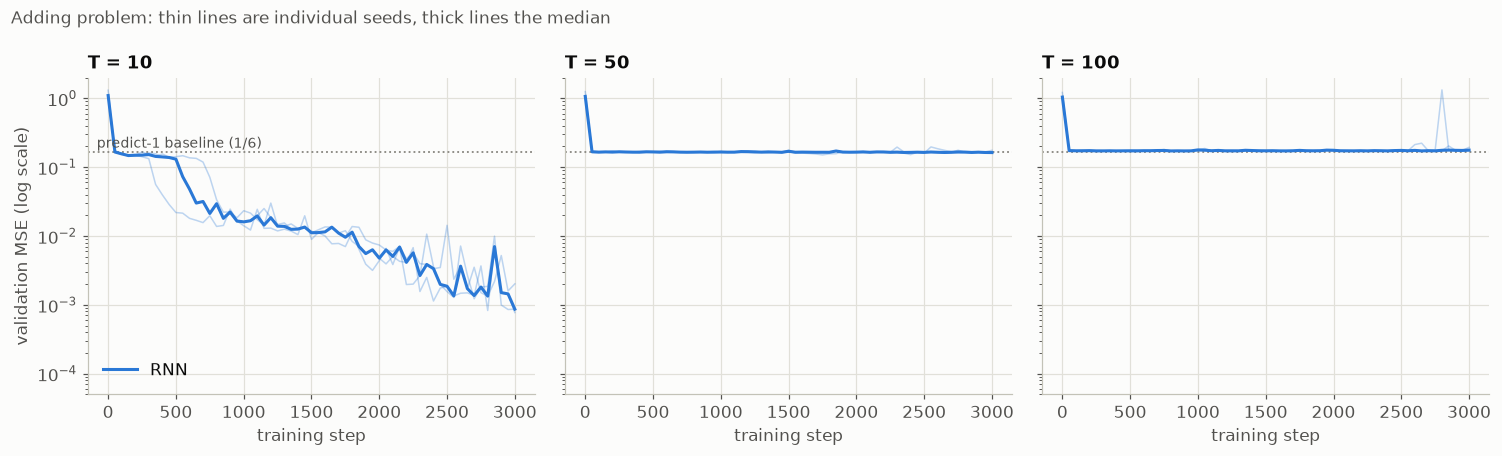

    T  model   final MSE (mean over seeds)  seeds solved   steps to solve (per seed)
   10  RNN                          0.0012           3/3            [950, 700, 1150]

   50  RNN                          0.1670           0/3          [None, None, None]

  100  RNN                          0.1810           0/3          [None, None, None]



In [12]:
run_grid(["RNN"], LENGTHS, SEEDS)
plot_training(["RNN"])
summarize(["RNN"])

**What to say about these results.** At $T = 10$ the vanilla RNN learns the task, but slowly and noisily. At $T = 50$ and $T = 100$ it stays at (or slightly above) the predict-1 baseline in every seed: it never learns to use the markers. That is exactly what the gradient plot predicted. The information about the first marked value has to travel through dozens of steps of multiplication by something smaller than one.

## 1.4 Can a better initialisation rescue it?

A fair objection: maybe the default initialisation is just unlucky. An **orthogonal** $W_{hh}$ is better optimized to carry gradients over a sequence of time steps. Let's try it at $T = 100$.

In [13]:
def report(label: str, name: str, T: int, init: str="default") -> str:
    c = curves(name, T, init)
    print(f"{label:30s} final MSE per seed = {[round(float(v), 4) for v in c[:, -1]]}   "
          f"steps to solve = {[steps_to_solve(r) for r in c]}")

In [14]:
run_grid(["RNN"], [100], SEEDS, init="orthogonal")
print()
report("vanilla RNN, default init", "RNN", 100)
report("vanilla RNN, orthogonal W_hh", "RNN", 100, init="orthogonal")


vanilla RNN, default init      final MSE per seed = [0.1939, 0.1768, 0.1722]   steps to solve = [None, None, None]
vanilla RNN, orthogonal W_hh   final MSE per seed = [0.1754, 0.1725, 0.1747]   steps to solve = [None, None, None]


**Takeaway of Part 1.** In our runs, orthogonal initialisation did not rescue the vanilla RNN at $T = 100$: no seed solved the task. (We did not try everything, such as other learning rates, much longer training or other architectures, so read this as "*not rescued by the current setup*", not as a proof that no vanilla RNN can solve the task.) The problem is structural: a single multiplicative path from the past to the present has nothing to stop the signal from shrinking.

**Next:** give the network a path along which the signal does *not* have to be squashed at every step. That is the idea behind the LSTM.